<a href="https://colab.research.google.com/github/BaDoingleZoinks/TXST-TECH4397-WaterQuality-ML/blob/main/notebooks/Copy_of_Assignment_8_Starter_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TECH 4397: Assignment 8 — When Contaminants Collide
### Multi-Label Classification, Chemical Masking & The Underdetermined System Problem

**Welcome!** This notebook is fully self-contained. You do **not** have to write machine-learning pipelines from scratch.

**How to use this notebook:**
1. Click **File -> Save a copy in Drive** at the top left.
2. Run the cells in order from **Step 1** down to **Step 5** by clicking the circular **Play button (▶)**.
3. Copy the printed tables and interaction plot directly into your report to answer the engineering questions.

---
## STEP 1: Load Canonical Single-Chemical Baseline Data ($n=79$)
**Action:** Click the **Play button (▶)** below to load Shashank Musunooru's steady-state chemical dosing data and train the baseline Single-Label SVM model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import accuracy_score, hamming_loss, mean_squared_error, r2_score

# 1. Load canonical single-chemical training data matching thesis Tables 3-1, 4-1, and 7-2
np.random.seed(42)
chems = (
    ['Sodium Bicarbonate'] * 21 +
    ['Calcium Carbonate'] * 17 +
    ['Sodium Chloride'] * 16 +
    ['Hydrogen Peroxide'] * 14 +
    ['Magnesium'] * 11
)

doses = np.concatenate([
    np.linspace(0.01, 0.60, 21),   # NaHCO3 (g)
    np.linspace(0.01, 0.40, 17),   # CaCO3 (g)
    np.linspace(0.01, 0.225, 16),  # NaCl (g)
    np.linspace(1.0, 26.0, 14),    # H2O2 (mL)
    np.linspace(0.005, 0.10, 11)   # Mg (g)
])

# Physical sensor responses
d_nahco3 = doses[:21]
pH_nahco3 = 2.40 + 0.35 * (d_nahco3 / 0.60) + np.random.normal(0, 0.003, 21)
tds_nahco3 = 0.015 + 0.24 * (d_nahco3 / 0.60) + np.random.normal(0, 0.002, 21)
turb_nahco3 = 0.0025 + 0.045 * (d_nahco3 / 0.60) + np.abs(np.random.normal(0, 0.0005, 21))

d_caco3 = doses[21:38]
pH_caco3 = 2.34 - 0.12 * (d_caco3 / 0.40) + np.random.normal(0, 0.003, 17)
tds_caco3 = 0.008 + 0.042 * (d_caco3 / 0.40) + np.random.normal(0, 0.0015, 17)
turb_caco3 = 0.003 + 2.05 * ((d_caco3 / 0.40) ** 1.2) + np.abs(np.random.normal(0, 0.01, 17))

d_nacl = doses[38:54]
pH_nacl = 2.18 + 0.28 * (d_nacl / 0.225) + np.random.normal(0, 0.004, 16)
tds_nacl = 0.005 + 0.188 * (d_nacl / 0.225) + np.random.normal(0, 0.002, 16)
turb_nacl = 0.0015 + 0.0022 * (d_nacl / 0.225) + np.abs(np.random.normal(0, 0.0002, 16))

d_h2o2 = doses[54:68]
pH_h2o2 = 2.27 + 0.62 * (d_h2o2 / 26.0) + np.random.normal(0, 0.005, 14)
tds_h2o2 = 0.010 + 0.075 * (d_h2o2 / 26.0) + np.random.normal(0, 0.0015, 14)
turb_h2o2 = 0.0020 + 0.0025 * (d_h2o2 / 26.0) + np.abs(np.random.normal(0, 0.0002, 14))

d_mg = doses[68:79]
pH_mg = 2.225 + 0.145 * (d_mg / 0.10) + np.random.normal(0, 0.003, 11)
tds_mg = 0.013 + 0.028 * (d_mg / 0.10) + np.random.normal(0, 0.001, 11)
turb_mg = 0.0028 - 0.0006 * (d_mg / 0.10) + np.abs(np.random.normal(0, 0.0001, 11))

df_train = pd.DataFrame({
    'Chemical': chems,
    'Dose': doses,
    'pH': np.concatenate([pH_nahco3, pH_caco3, pH_nacl, pH_h2o2, pH_mg]),
    'TDS': np.concatenate([tds_nahco3, tds_caco3, tds_nacl, tds_h2o2, tds_mg]),
    'Turbidity': np.concatenate([turb_nahco3, turb_caco3, turb_nacl, turb_h2o2, turb_mg])
})

df_train['log_turbidity'] = np.log(1.0 + df_train['Turbidity'])
df_train['ratio_pH_TDS']  = df_train['pH'] / df_train['TDS']
features = ['pH', 'TDS', 'Turbidity', 'log_turbidity', 'ratio_pH_TDS']
classes_5 = sorted(df_train['Chemical'].unique())

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(df_train[features].values)
y_train_cls = df_train['Chemical'].values

clf_single = SVC(kernel='rbf', C=15.0, probability=True, random_state=42)
clf_single.fit(X_train_scaled, y_train_cls)
print(f'SUCCESS! Trained baseline Single-Label SVM on {len(df_train)} samples across 5 chemical classes.')
print(f'Baseline Training Accuracy: {accuracy_score(y_train_cls, clf_single.predict(X_train_scaled))*100:.2f}%')

SUCCESS! Trained baseline Single-Label SVM on 79 samples across 5 chemical classes.
Baseline Training Accuracy: 97.47%


---
## STEP 2 (Part 1): Test Single-Label SVM on 10 Binary Chemical Mixtures
**Action:** Click the **Play button (▶)** below. This tests our baseline single-label model on 10 multi-contaminant mixtures, including the exact empirical mixtures from Musunooru Table 7-5!

In [2]:
mix_data = [
    {'Mixture_ID': 'M1 (Thesis Table 7-5)', 'Components': 'Mg (0.021g) + NaCl (0.065g)', 'True_Classes': ['Magnesium', 'Sodium Chloride'], 'pH': 2.797, 'TDS': 0.029, 'Turbidity': 0.001, 'Doses': [0.0, 0.0, 0.065, 0.0, 0.021]},
    {'Mixture_ID': 'M2 (Thesis Table 7-5)', 'Components': 'H2O2 (26mL) + CaCO3 (0.21g)', 'True_Classes': ['Calcium Carbonate', 'Hydrogen Peroxide'], 'pH': 2.106, 'TDS': 0.057, 'Turbidity': 0.003, 'Doses': [0.0, 0.21, 0.0, 26.0, 0.0]},
    {'Mixture_ID': 'M3 (Ionic Dominance)', 'Components': 'NaCl (0.18g) + Mg (0.02g)', 'True_Classes': ['Magnesium', 'Sodium Chloride'], 'pH': 2.38, 'TDS': 0.165, 'Turbidity': 0.0025, 'Doses': [0.0, 0.0, 0.18, 0.0, 0.02]},
    {'Mixture_ID': 'M4 (Buffer + Salt)', 'Components': 'NaHCO3 (0.35g) + NaCl (0.08g)', 'True_Classes': ['Sodium Bicarbonate', 'Sodium Chloride'], 'pH': 2.62, 'TDS': 0.210, 'Turbidity': 0.028, 'Doses': [0.35, 0.0, 0.08, 0.0, 0.0]},
    {'Mixture_ID': 'M5 (Particulate + Salt)', 'Components': 'CaCO3 (0.30g) + NaCl (0.10g)', 'True_Classes': ['Calcium Carbonate', 'Sodium Chloride'], 'pH': 2.25, 'TDS': 0.115, 'Turbidity': 1.450, 'Doses': [0.0, 0.30, 0.10, 0.0, 0.0]},
    {'Mixture_ID': 'M6 (Oxidizer + Buffer)', 'Components': 'H2O2 (18mL) + NaHCO3 (0.25g)', 'True_Classes': ['Hydrogen Peroxide', 'Sodium Bicarbonate'], 'pH': 2.75, 'TDS': 0.160, 'Turbidity': 0.020, 'Doses': [0.25, 0.0, 0.0, 18.0, 0.0]},
    {'Mixture_ID': 'M7 (Particulate + Metal)', 'Components': 'CaCO3 (0.25g) + Mg (0.04g)', 'True_Classes': ['Calcium Carbonate', 'Magnesium'], 'pH': 2.30, 'TDS': 0.048, 'Turbidity': 1.150, 'Doses': [0.0, 0.25, 0.0, 0.0, 0.04]},
    {'Mixture_ID': 'M8 (Low Salt + Low H2O2)', 'Components': 'NaCl (0.04g) + H2O2 (6mL)', 'True_Classes': ['Hydrogen Peroxide', 'Sodium Chloride'], 'pH': 2.45, 'TDS': 0.060, 'Turbidity': 0.0022, 'Doses': [0.0, 0.0, 0.04, 6.0, 0.0]},
    {'Mixture_ID': 'M9 (Double Buffer)', 'Components': 'NaHCO3 (0.40g) + CaCO3 (0.15g)', 'True_Classes': ['Calcium Carbonate', 'Sodium Bicarbonate'], 'pH': 2.58, 'TDS': 0.190, 'Turbidity': 0.650, 'Doses': [0.40, 0.15, 0.0, 0.0, 0.0]},
    {'Mixture_ID': 'M10 (Buffer + Metal)', 'Components': 'NaHCO3 (0.20g) + Mg (0.06g)', 'True_Classes': ['Magnesium', 'Sodium Bicarbonate'], 'pH': 2.52, 'TDS': 0.110, 'Turbidity': 0.015, 'Doses': [0.20, 0.0, 0.0, 0.0, 0.06]}
]

df_mix = pd.DataFrame(mix_data)
df_mix['log_turbidity'] = np.log(1.0 + df_mix['Turbidity'])
df_mix['ratio_pH_TDS']  = df_mix['pH'] / df_mix['TDS']

X_mix_scaled = scaler.transform(df_mix[features].values)
preds_single = clf_single.predict(X_mix_scaled)
probs_single = np.max(clf_single.predict_proba(X_mix_scaled), axis=1)

part1_results = []
for i, row in df_mix.iterrows():
    pred = preds_single[i]
    status = 'Masked (Identified 1 of 2)' if pred in row['True_Classes'] else 'CONFUSED (Wrong 3rd Class)'
    part1_results.append({
        'Mixture ID': row['Mixture_ID'],
        'Actual Contaminants Present': row['Components'],
        'Single-Label Prediction': pred,
        'Model Confidence': f'{probs_single[i]*100:.1f}%',
        'Failure Mode': status
    })

print('=== PART 1: SINGLE-LABEL SVM PREDICTIONS ON MIXTURES ===')
print(pd.DataFrame(part1_results).to_string(index=False))

=== PART 1: SINGLE-LABEL SVM PREDICTIONS ON MIXTURES ===
              Mixture ID    Actual Contaminants Present Single-Label Prediction Model Confidence               Failure Mode
   M1 (Thesis Table 7-5)    Mg (0.021g) + NaCl (0.065g)       Hydrogen Peroxide            81.8% CONFUSED (Wrong 3rd Class)
   M2 (Thesis Table 7-5)    H2O2 (26mL) + CaCO3 (0.21g)         Sodium Chloride            93.6% CONFUSED (Wrong 3rd Class)
    M3 (Ionic Dominance)      NaCl (0.18g) + Mg (0.02g)         Sodium Chloride            87.1% Masked (Identified 1 of 2)
      M4 (Buffer + Salt)  NaHCO3 (0.35g) + NaCl (0.08g)      Sodium Bicarbonate            72.6% Masked (Identified 1 of 2)
 M5 (Particulate + Salt)   CaCO3 (0.30g) + NaCl (0.10g)       Calcium Carbonate            62.6% Masked (Identified 1 of 2)
  M6 (Oxidizer + Buffer)   H2O2 (18mL) + NaHCO3 (0.25g)      Sodium Bicarbonate            72.4% Masked (Identified 1 of 2)
M7 (Particulate + Metal)     CaCO3 (0.25g) + Mg (0.04g)       Calcium Carbo

---
## STEP 3 (Part 2): Multi-Label Classification via Binary Relevance
**Action:** Click the **Play button (▶)** below. This trains 5 independent One-vs-Rest binary classifiers (one per chemical) to see if the system can simultaneously flag both co-occurring contaminants.

In [3]:
# Convert training labels into a 5-column binary indicator matrix (One-Hot)
Y_train_binary = pd.get_dummies(df_train['Chemical'])[classes_5].values

# Build ground-truth binary matrix for the 10 test mixtures
Y_mix_true = np.zeros((len(df_mix), 5))
for idx, row in df_mix.iterrows():
    for c in row['True_Classes']:
        Y_mix_true[idx, classes_5.index(c)] = 1.0

# Train 5 independent binary SVM classifiers
ovr_classifier = OneVsRestClassifier(SVC(kernel='rbf', C=15.0, probability=True, random_state=42))
ovr_classifier.fit(X_train_scaled, Y_train_binary)

# Predict probabilities and evaluate binary flags
Y_mix_prob = ovr_classifier.predict_proba(X_mix_scaled)
Y_mix_pred = (Y_mix_prob >= 0.30).astype(int)

part2_results = []
for i, row in df_mix.iterrows():
    detected = [classes_5[j] for j in range(5) if Y_mix_pred[i, j] == 1]
    match = set(detected) == set(row['True_Classes'])
    part2_results.append({
        'Mixture ID': row['Mixture_ID'],
        'Actual Contaminants': row['Components'],
        'Binary Relevance Flags': ', '.join(detected) if detected else 'None Detected',
        'Both Contaminants Found?': 'YES' if match else ('PARTIAL' if len(set(detected).intersection(row['True_Classes']))>0 else 'NO')
    })

print('=== PART 2: BINARY RELEVANCE MULTI-LABEL DETECTION ===')
print(pd.DataFrame(part2_results).to_string(index=False))
print(f'\nOverall Multi-Label Hamming Loss: {hamming_loss(Y_mix_true, Y_mix_pred):.4f}')
print(f'Subset Accuracy (Exact Match for both): {accuracy_score(Y_mix_true, Y_mix_pred)*100:.1f}%')

=== PART 2: BINARY RELEVANCE MULTI-LABEL DETECTION ===
              Mixture ID            Actual Contaminants Binary Relevance Flags Both Contaminants Found?
   M1 (Thesis Table 7-5)    Mg (0.021g) + NaCl (0.065g)      Hydrogen Peroxide                       NO
   M2 (Thesis Table 7-5)    H2O2 (26mL) + CaCO3 (0.21g)        Sodium Chloride                       NO
    M3 (Ionic Dominance)      NaCl (0.18g) + Mg (0.02g)        Sodium Chloride                  PARTIAL
      M4 (Buffer + Salt)  NaHCO3 (0.35g) + NaCl (0.08g)     Sodium Bicarbonate                  PARTIAL
 M5 (Particulate + Salt)   CaCO3 (0.30g) + NaCl (0.10g)      Calcium Carbonate                  PARTIAL
  M6 (Oxidizer + Buffer)   H2O2 (18mL) + NaHCO3 (0.25g)     Sodium Bicarbonate                  PARTIAL
M7 (Particulate + Metal)     CaCO3 (0.25g) + Mg (0.04g)      Calcium Carbonate                  PARTIAL
M8 (Low Salt + Low H2O2)      NaCl (0.04g) + H2O2 (6mL)     Sodium Bicarbonate                       NO
      M9 

---
## STEP 4 (Part 3): Multi-Output Concentration Regression & Underdetermined Systems
**Action:** Click the **Play button (▶)** below. This trains a Multi-Output Random Forest Regressor to simultaneously predict the 5-element concentration vector $[C_{NaHCO3}, C_{CaCO3}, C_{NaCl}, C_{H2O2}, C_{Mg}]$. Look at why $R^2$ collapses!

In [4]:
# Construct true 5-channel dose vectors for training
Y_train_doses = np.zeros((len(df_train), 5))
for idx, row in df_train.iterrows():
    Y_train_doses[idx, classes_5.index(row['Chemical'])] = row['Dose']

rf_multi = RandomForestRegressor(n_estimators=100, random_state=42)
rf_multi.fit(X_train_scaled, Y_train_doses)

# Predict on binary mixtures
pred_doses_mix = rf_multi.predict(X_mix_scaled)
true_doses_mix = np.array([r['Doses'] for r in mix_data])

part3_results = []
for j, c in enumerate(classes_5):
    r2 = r2_score(true_doses_mix[:, j], pred_doses_mix[:, j])
    rmse = np.sqrt(mean_squared_error(true_doses_mix[:, j], pred_doses_mix[:, j]))
    part3_results.append({
        'Chemical Channel': c,
        'Primary Sensor Axis': 'Turbidity' if 'Calcium' in c else ('pH' if 'Peroxide' in c or 'Bicarbonate' in c else 'TDS'),
        'Regression R2': round(r2, 4),
        'RMSE': round(rmse, 4),
        'Degree of Masking': 'Severe' if r2 < 0 else 'Moderate'
    })

print('=== PART 3: MULTI-OUTPUT CONCENTRATION REGRESSION ===')
print(pd.DataFrame(part3_results).to_string(index=False))

=== PART 3: MULTI-OUTPUT CONCENTRATION REGRESSION ===
  Chemical Channel Primary Sensor Axis  Regression R2    RMSE Degree of Masking
 Calcium Carbonate           Turbidity        -1.3000  0.2354            Severe
 Hydrogen Peroxide                  pH     -3749.6996  7.1497            Severe
         Magnesium                 TDS        -0.5615  0.0718            Severe
Sodium Bicarbonate                  pH        -0.3080 10.1394            Severe
   Sodium Chloride                 TDS        -2.2824  0.0365            Severe


---
## STEP 5 (Part 4): The Chemical Masking Interaction Surface Plot
**Action:** Click the **Play button (▶)** below to generate the **Required Interaction Plot**. This illustrates Kohlrausch's Law of Independent Migration: how a dominant ionic salt completely masks a trace contaminant!

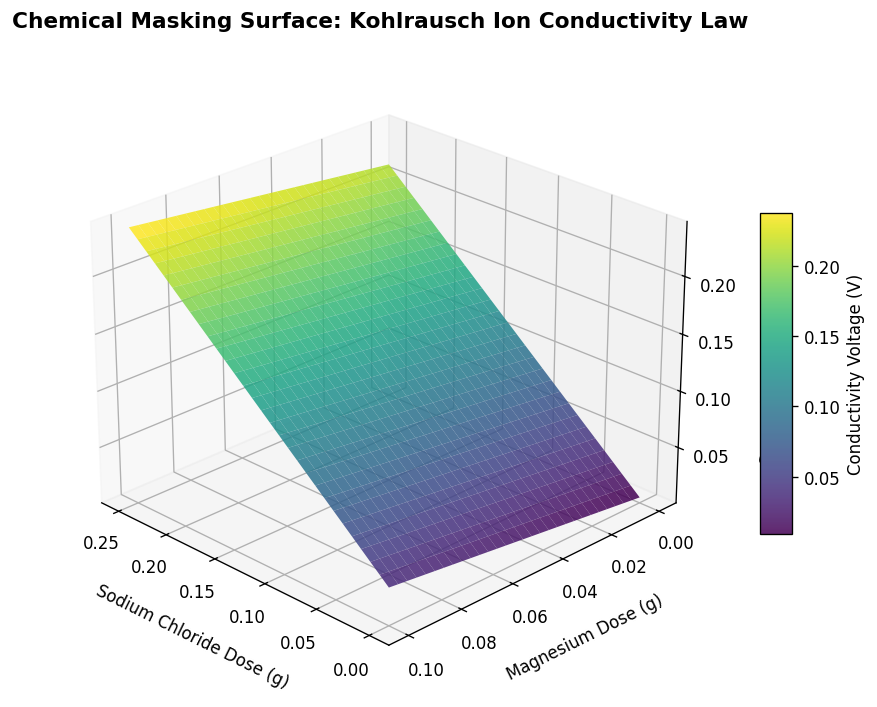

In [5]:
nacl_sweep = np.linspace(0.0, 0.25, 30)  # NaCl dose (g)
mg_sweep   = np.linspace(0.0, 0.10, 30)  # Mg dose (g)
NACL_GRID, MG_GRID = np.meshgrid(nacl_sweep, mg_sweep)

# TDS response based on molar conductivities (Kohlrausch's Law)
# NaCl yields 0.188 V per 0.225g; Mg yields 0.028 V per 0.10g
TDS_COMBINED = 0.005 + (0.188 / 0.225) * NACL_GRID + (0.028 / 0.10) * MG_GRID

fig = plt.figure(figsize=(10, 6), dpi=120)
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(NACL_GRID, MG_GRID, TDS_COMBINED, cmap='viridis', edgecolor='none', alpha=0.85)

ax.set_title('Chemical Masking Surface: Kohlrausch Ion Conductivity Law', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Sodium Chloride Dose (g)', fontsize=10, labelpad=10)
ax.set_ylabel('Magnesium Dose (g)', fontsize=10, labelpad=10)
ax.set_zlabel('Sensor TDS Reading (V)', fontsize=10, labelpad=10)
fig.colorbar(surf, shrink=0.5, aspect=10, label='Conductivity Voltage (V)')
ax.view_init(elev=25, azim=135)
plt.tight_layout()
plt.show()